In [1]:
from utils import prepare_dataframe

df = prepare_dataframe("merged.csv",False,False)
resulting_label_count = df['labels'].nunique()
df

labels
enhancement    37586
bug            32864
clean          17263
performance     5392
refactor        4596
Name: count, dtype: int64
labels
enhancement    37586
bug            32864
clean          17263
Name: count, dtype: int64


,full_repo_name,labels,patch,index
1909,google/gson,enhancement,"@@ -289,24 +289,34 @@ public final T fromJsonT...",1909
1910,google/gson,enhancement,"@@ -28,23 +28,50 @@\n public class TypeAdapter...",1910
1947,google/conscrypt,enhancement,"@@ -1017,6 +1017,8 @@ public SSLEngineResult w...",1947
1948,google/conscrypt,enhancement,"@@ -293,13 +293,15 @@ public void removeValue(...",1948
1949,google/conscrypt,enhancement,"@@ -22,6 +22,7 @@\n import java.net.InetSocket...",1949
...,...,...,...,...
96453,apache/drill,clean,"@@ -53,7 +53,6 @@\n import org.junit.experimen...",96453
96454,apache/drill,clean,"@@ -25,14 +25,17 @@\n import org.apache.drill....",96454
96455,apache/drill,clean,"@@ -75,6 +75,8 @@ public static void initSplun...",96455
96456,apache/drill,clean,"@@ -17,6 +17,7 @@\n */\n package org.apache.d...",96456


In [2]:
embedding_directory = 'embeddings/GCB_Pooler_embeddings_patch_before_largewithcodedata_Xlimit3label'
model_directory = 'models/two_pipelines_StScaler_pooler_6layers_invertednn_100epoch_batch_normalization_best_accuracy.pth'

In [ ]:
# Sadece apache repoları seçiliyor
df = df[df['full_repo_name'].str.startswith('apache', na=False)]

# Test için veri setini dengeleme
label_enh = df[df['labels'] == 'enhancement']
label_bug = df[df['labels'] == 'bug']
label_cln = df[df['labels'] == 'clean']

min_samples = min(len(label_enh), len(label_bug), len(label_cln))
sampled_enh = label_enh.sample(n=min_samples, random_state=1)
sampled_bug = label_bug.sample(n=min_samples, random_state=1)
sampled_cln = label_cln.sample(n=min_samples, random_state=1)
df = pd.concat([sampled_enh, sampled_bug, sampled_cln])

In [3]:
import pandas as pd
import torch


# One-hot encoding ile labels sütununu dönüştürme
df_encoded_labels = pd.get_dummies(df, columns=['labels'])
df_encoded_repo = pd.get_dummies(df, columns=['full_repo_name'])

# Özellikler ve etiketler
X_repo = df_encoded_repo.drop(columns=['labels','patch','index'])
X_repo = X_repo.astype(int)

# y = df_encoded.drop(columns=['content_before', 'content_after', 'tokens'])
y = df_encoded_labels.drop(columns=['patch', 'full_repo_name','index'])
y = y.astype(int) # convert it 0,1     instead of true, false 

df['label_tensor'] =[torch.tensor(row,dtype=torch.float32) for row in y.values] 
df['repo_name_tensor'] =[torch.tensor(row,dtype=torch.float32) for row in X_repo.values] 

df = df.drop(columns=['full_repo_name', 'labels','patch'])


print(df['label_tensor'][0] )
print(df['repo_name_tensor'][0] )
df

tensor([0., 1., 0.])
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.,

,index,label_tensor,repo_name_tensor
1909,1909,"[tensor(0.), tensor(0.), tensor(1.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
1910,1910,"[tensor(0.), tensor(0.), tensor(1.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
1947,1947,"[tensor(0.), tensor(0.), tensor(1.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
1948,1948,"[tensor(0.), tensor(0.), tensor(1.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
1949,1949,"[tensor(0.), tensor(0.), tensor(1.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
...,...,...,...
96453,96453,"[tensor(0.), tensor(1.), tensor(0.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
96454,96454,"[tensor(0.), tensor(1.), tensor(0.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
96455,96455,"[tensor(0.), tensor(1.), tensor(0.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
96456,96456,"[tensor(0.), tensor(1.), tensor(0.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0...."


In [4]:
from utils import load_embeddings_from_directory_for_df
import pandas as pd

df = load_embeddings_from_directory_for_df(directory_path=embedding_directory,df=df)


  0%|          | 0/87713 [00:00<?, ?it/s]

In [5]:
from sklearn.model_selection import train_test_split

X_index = df[['index']]  
# Split the code data into test, train and validation sets
X_index_train, X_index_test = train_test_split(X_index, test_size=0.3, random_state=42) #random_state: 0,3074,42
X_index_test, X_index_val = train_test_split(X_index_test, test_size=0.5, random_state=42)

In [6]:
import gc
import torch

df_train = df[df['index'].isin(X_index_train['index'].values)].reset_index(drop=True)
df_val = df[df['index'].isin(X_index_val['index'].values)].reset_index(drop=True)
df_test = df[df['index'].isin(X_index_test['index'].values)].reset_index(drop=True)

torch.cuda.empty_cache()

df_train

,index,label_tensor,repo_name_tensor,embedding
0,1909,"[tensor(0.), tensor(0.), tensor(1.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0....","[tensor(-0.5895), tensor(-0.1560), tensor(-0.0..."
1,1910,"[tensor(0.), tensor(0.), tensor(1.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0....","[tensor(-0.5127), tensor(-0.1172), tensor(-0.0..."
2,1947,"[tensor(0.), tensor(0.), tensor(1.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0....","[tensor(-0.4870), tensor(-0.0234), tensor(0.31..."
3,1948,"[tensor(0.), tensor(0.), tensor(1.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0....","[tensor(-0.4556), tensor(-0.1558), tensor(-0.1..."
4,1949,"[tensor(0.), tensor(0.), tensor(1.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0....","[tensor(-0.4414), tensor(-0.0394), tensor(-0.0..."
...,...,...,...,...
61394,96452,"[tensor(0.), tensor(1.), tensor(0.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0....","[tensor(-0.4837), tensor(-0.0799), tensor(-0.0..."
61395,96453,"[tensor(0.), tensor(1.), tensor(0.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0....","[tensor(-0.3640), tensor(-0.1579), tensor(0.08..."
61396,96454,"[tensor(0.), tensor(1.), tensor(0.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0....","[tensor(-0.4033), tensor(-0.2856), tensor(0.03..."
61397,96455,"[tensor(0.), tensor(1.), tensor(0.)]","[tensor(0.), tensor(0.), tensor(0.), tensor(0....","[tensor(-0.3929), tensor(-0.0306), tensor(-0.0..."


In [7]:
from torch.utils.data import DataLoader, Dataset
from utils import load_embedding_from_directory

# Custom Dataset Class to handle the dataframe
class CodeDataset(Dataset):
    def __init__(self, df):
        self.df = df
        self.id_list = df['index'].values 

    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
    
        index = self.id_list[idx]  

        tensor_3d = self.df.loc[self.df['index'] == index, 'embedding'].iloc[0]
        repo_name_tensor = self.df.loc[self.df['index'] == index, 'repo_name_tensor'].iloc[0]
        label_tensor = self.df.loc[self.df['index'] == index, 'label_tensor'].iloc[0]
        
        #print(f"{repo_name_tensor.shape} {tensor_3d.shape} {label_tensor.shape}")
        #print("-------------------------------")
        
        #Flattening
        #embedding = torch.flatten(tensor_3d)
        embedding = tensor_3d
        return embedding, label_tensor, repo_name_tensor, index


In [8]:
# Create DataLoader

# Creating a DataLoader
def create_dataloader(df, batch_size=32, shuffle=True):
    dataset = CodeDataset(df)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

batch_size = 128
test_loader = create_dataloader(df=df_test, batch_size=batch_size)
train_loader = create_dataloader(df=df_train, batch_size=batch_size)
val_loader = create_dataloader(df=df_val,batch_size=batch_size)

full_loader_for_scaler = create_dataloader(df=df, batch_size=512)

In [9]:
from sklearn.preprocessing import StandardScaler
import tqdm

scaler = StandardScaler()

for batch_X, batch_y, batch_X_repo, idx in tqdm.tqdm_notebook(full_loader_for_scaler):
    scaler.partial_fit(batch_X)

/tmp/ipykernel_4116550/796712526.py:6: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for batch_X, batch_y, batch_X_repo, idx in tqdm.tqdm_notebook(full_loader_for_scaler):


  0%|          | 0/172 [00:00<?, ?it/s]

In [10]:
import joblib

# Save scaler into file
joblib.dump(scaler, 'scalers/scaler_pooler_3labels_15300.pkl')

['scalers/scaler_pooler_3labels_15300.pkl']

In [11]:
import joblib

# Load scaler from file
scaler = joblib.load('scalers/scaler_pooler_3labels_15300.pkl')

In [12]:
# import torch.nn as nn

# # Define the ANN model
# class SinglePipelineCodeDiffNN(nn.Module):
#     def __init__(self, code_input_size, hidden_sizes, output_size, dropout_rate=0.05):
#         super(SinglePipelineCodeDiffNN, self).__init__()
        
#         # Pipeline for code embeddings
#         self.code_fc1 = nn.Linear(code_input_size, hidden_sizes[0])
#         self.code_relu1 = nn.ReLU()
#         self.code_dropout1 = nn.Dropout(dropout_rate)
        
#         self.code_fc2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
#         self.code_relu2 = nn.ReLU()
#         self.code_dropout2 = nn.Dropout(dropout_rate)

#         self.code_fc3 = nn.Linear(hidden_sizes[1], hidden_sizes[2])
#         self.code_relu3 = nn.ReLU()
#         self.code_dropout3 = nn.Dropout(dropout_rate)

#         self.code_fc4 = nn.Linear(hidden_sizes[2], hidden_sizes[3])
#         self.code_relu4 = nn.ReLU()
#         self.code_dropout4 = nn.Dropout(dropout_rate)

#         self.code_fc5 = nn.Linear(hidden_sizes[3], hidden_sizes[4])
#         self.code_relu5 = nn.ReLU()
        
#         self.code_fc_out = nn.Linear(hidden_sizes[4], output_size)

        
#     def forward(self, code_x):
#         # Process code embeddings
#         code_x = self.code_fc1(code_x)
#         code_x = self.code_relu1(code_x)
#         code_x = self.code_dropout1(code_x)
        
#         code_x = self.code_fc2(code_x)
#         code_x = self.code_relu2(code_x)
#         code_x = self.code_dropout2(code_x)

#         code_x = self.code_fc3(code_x)
#         code_x = self.code_relu3(code_x)
#         code_x = self.code_dropout3(code_x)

#         code_x = self.code_fc4(code_x)
#         code_x = self.code_relu4(code_x)
#         code_x = self.code_dropout4(code_x)

#         code_x = self.code_fc5(code_x)
#         code_x = self.code_relu5(code_x)

#         # Final output
#         output = self.code_fc_out(code_x)
#         return output


In [13]:
import torch.nn as nn

# Define the ANN model
class CodeDiffNN(nn.Module):
    def __init__(self, code_input_size, repo_input_size, hidden_sizes_embedding_pipeline,hidden_sizes_reponame_pipeline,hidden_sizes_merged_pipeline, output_size, dropout_rate):
        super(CodeDiffNN, self).__init__()
        
        # Pipeline for code embeddings
        self.code_fc1 = nn.Linear(code_input_size, hidden_sizes_embedding_pipeline[0])
        self.code_bn1 = nn.BatchNorm1d(hidden_sizes_embedding_pipeline[0])
        self.code_relu1 = nn.ReLU()
        self.code_dropout1 = nn.Dropout(dropout_rate)
        
        self.code_fc2 = nn.Linear(hidden_sizes_embedding_pipeline[0], hidden_sizes_embedding_pipeline[1])
        self.code_bn2 = nn.BatchNorm1d(hidden_sizes_embedding_pipeline[1])
        self.code_relu2 = nn.ReLU()
        self.code_dropout2 = nn.Dropout(dropout_rate)
        
        self.code_fc3 = nn.Linear(hidden_sizes_embedding_pipeline[1], hidden_sizes_embedding_pipeline[2])
        self.code_bn3 = nn.BatchNorm1d(hidden_sizes_embedding_pipeline[2])
        self.code_relu3 = nn.ReLU()
        self.code_dropout3 = nn.Dropout(dropout_rate)  
        
        
        # Pipeline for repo names
        self.repo_fc1 = nn.Linear(repo_input_size, hidden_sizes_reponame_pipeline[0])
        self.repo_bn1 = nn.BatchNorm1d(hidden_sizes_reponame_pipeline[0])
        self.repo_relu1 = nn.ReLU()
        self.repo_dropout1 = nn.Dropout(dropout_rate)
        
        self.repo_fc2 = nn.Linear(hidden_sizes_reponame_pipeline[0], hidden_sizes_reponame_pipeline[1])
        self.repo_bn2 = nn.BatchNorm1d(hidden_sizes_reponame_pipeline[1])
        self.repo_relu2 = nn.ReLU()
        self.repo_dropout2 = nn.Dropout(dropout_rate)

        
        # Combining the outputs of both pipelines
        combined_input_size = hidden_sizes_embedding_pipeline[2] + hidden_sizes_reponame_pipeline[1]   # Since we're combining two pipelines
        self.combined_fc1 = nn.Linear(combined_input_size, hidden_sizes_merged_pipeline[0])
        self.combined_bn1 = nn.BatchNorm1d(hidden_sizes_merged_pipeline[0])
        self.combined_relu1 = nn.ReLU()
        self.combined_dropout1 = nn.Dropout(dropout_rate)

        self.combined_fc2  = nn.Linear(hidden_sizes_merged_pipeline[0], hidden_sizes_merged_pipeline[1])
        self.combined_bn2 = nn.BatchNorm1d(hidden_sizes_merged_pipeline[1])
        self.combined_relu2  = nn.ReLU()
        self.combined_dropout2 = nn.Dropout(dropout_rate)
        
        self.combined_fc3  = nn.Linear(hidden_sizes_merged_pipeline[1], hidden_sizes_merged_pipeline[2])
        self.combined_bn3 = nn.BatchNorm1d(hidden_sizes_merged_pipeline[2])
        self.combined_relu3  = nn.ReLU()
        self.combined_dropout3 = nn.Dropout(dropout_rate)
        
        self.combined_fc4  = nn.Linear(hidden_sizes_merged_pipeline[2], hidden_sizes_merged_pipeline[3])
        self.combined_bn4 = nn.BatchNorm1d(hidden_sizes_merged_pipeline[3])
        self.combined_relu4  = nn.ReLU()
        self.combined_dropout4 = nn.Dropout(dropout_rate)

        # Output layer
        self.fc_out = nn.Linear(hidden_sizes_merged_pipeline[3], output_size)
        
    def forward(self, code_x, repo_x):
        # Process code embeddings
        code_x = self.code_fc1(code_x)
        code_x = self.code_bn1(code_x)
        code_x = self.code_relu1(code_x)
        code_x = self.code_dropout1(code_x)
        
        code_x = self.code_fc2(code_x)
        code_x = self.code_bn2(code_x)
        code_x = self.code_relu2(code_x)
        code_x = self.code_dropout2(code_x)
        
        code_x = self.code_fc3(code_x)
        code_x = self.code_bn3(code_x)
        code_x = self.code_relu3(code_x)
        code_x = self.code_dropout3(code_x)
        
        # Process repo names
        repo_x = self.repo_fc1(repo_x)
        repo_x = self.repo_bn1(repo_x)
        repo_x = self.repo_relu1(repo_x)
        repo_x = self.repo_dropout1(repo_x)
        
        repo_x = self.repo_fc2(repo_x)
        repo_x = self.repo_bn2(repo_x)
        repo_x = self.repo_relu2(repo_x)
        repo_x = self.repo_dropout2(repo_x)
        
        # Combine both outputs
        combined_x = torch.cat((code_x, repo_x), dim=1)
        
        # Process the combined output
        combined_x = self.combined_fc1(combined_x)
        combined_x = self.combined_bn1(combined_x)
        combined_x = self.combined_relu1(combined_x)
        combined_x = self.combined_dropout1(combined_x)

        combined_x = self.combined_fc2(combined_x)
        combined_x = self.combined_bn2(combined_x)
        combined_x = self.combined_relu2(combined_x)
        combined_x = self.combined_dropout2(combined_x)
        
        combined_x = self.combined_fc3(combined_x)
        combined_x = self.combined_bn3(combined_x)
        combined_x = self.combined_relu3(combined_x)
        combined_x = self.combined_dropout3(combined_x)
        
        combined_x = self.combined_fc4(combined_x)
        combined_x = self.combined_bn4(combined_x)
        combined_x = self.combined_relu4(combined_x)
        combined_x = self.combined_dropout4(combined_x)
        
        # Final output
        output = self.fc_out(combined_x)
        return output


In [14]:
# import torch.nn as nn

# # Define the ANN model
# class CodeDiffNN(nn.Module):
#     def __init__(self, code_embedding_dim, repo_input_size, hidden_sizes, output_size, dropout_rate=0.001):
#         super(CodeDiffNN, self).__init__()
        
#         # Pipeline for code embeddings (Conv2D for 2D input)
#         # Set in_channels to the embedding dimension (e.g., 768)
#         # Increase out_channels to better handle high-dimensional inputs
#         self.code_conv1 = nn.Conv2d(in_channels=code_embedding_dim, out_channels=128, kernel_size=3, padding=1)
#         self.code_relu1 = nn.ReLU()
#         self.code_dropout1 = nn.Dropout(dropout_rate)
        
#         self.code_conv2 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
#         self.code_relu2 = nn.ReLU()
#         self.code_dropout2 = nn.Dropout(dropout_rate)

#         # Assuming a fixed input size for flattening (adjust this based on the input size and conv layer operations)
#         self.code_flatten = nn.Flatten()

#         # Flattened output from conv layers should map to hidden_sizes[1]
#         self.code_fc = nn.Linear(256*512, hidden_sizes[1])  # Modify based on input dimensions
        
#         # Pipeline for repo names (still using Linear layers for 1D input)
#         self.repo_fc1 = nn.Linear(repo_input_size, hidden_sizes[0])
#         self.repo_relu1 = nn.ReLU()
#         self.repo_dropout1 = nn.Dropout(dropout_rate)
        
#         self.repo_fc2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
#         self.repo_relu2 = nn.ReLU()
#         self.repo_dropout2 = nn.Dropout(dropout_rate)
        
#         # Combining the outputs of both pipelines
#         combined_input_size = hidden_sizes[1] * 2  # Since we're combining two pipelines
#         self.fc_combined = nn.Linear(combined_input_size, hidden_sizes[2])
#         self.relu_combined = nn.ReLU()
#         self.dropout_combined = nn.Dropout(dropout_rate)

#         # Output layer
#         self.fc_out = nn.Linear(hidden_sizes[2], output_size)
        
#     def forward(self, code_x, repo_x):
#         # Reformat input
#         # [batch_size, sequence_length, embedding_dim] -> [batch_size, embedding_dim, sequence_length, 1]
#         code_x = code_x.permute(0, 2, 1).unsqueeze(-1)
        
#         # Process code embeddings (2D input)
#         code_x = self.code_conv1(code_x)
#         code_x = self.code_relu1(code_x)
#         code_x = self.code_dropout1(code_x)
        
#         code_x = self.code_conv2(code_x)
#         code_x = self.code_relu2(code_x)
#         code_x = self.code_dropout2(code_x)
        
#         # Flatten the output from the conv layers before the fully connected layer
#         code_x = self.code_flatten(code_x)
#         code_x = self.code_fc(code_x)
        
#         # Process repo names (1D input)
#         repo_x = self.repo_fc1(repo_x)
#         repo_x = self.repo_relu1(repo_x)
#         repo_x = self.repo_dropout1(repo_x)
        
#         repo_x = self.repo_fc2(repo_x)
#         repo_x = self.repo_relu2(repo_x)
#         repo_x = self.repo_dropout2(repo_x)
        
#         # Combine both outputs
#         combined_x = torch.cat((code_x, repo_x), dim=1)
        
#         # Process the combined output
#         combined_x = self.fc_combined(combined_x)
#         combined_x = self.relu_combined(combined_x)
#         combined_x = self.dropout_combined(combined_x)
        
#         # Final output
#         output = self.fc_out(combined_x)
#         return output

In [15]:
import torch.optim as optim
# Define model parameters

code_embedding_dim = df_train['embedding'][5].shape[0]

repo_input_size = len(df_train['repo_name_tensor'][0])
#hidden_sizes = [1024, 512, 256, 128]
hidden_sizes_embedding_pipeline = [1024, 2048, 4096]
hidden_sizes_reponame_pipeline = [512, 1024]
hidden_sizes_merged_pipeline = [2048, 1024, 512, 256]
output_size = resulting_label_count
dropout_rate = 0.05

device = "cuda:0"
model = CodeDiffNN(code_embedding_dim, repo_input_size, hidden_sizes_embedding_pipeline,hidden_sizes_reponame_pipeline,hidden_sizes_merged_pipeline, output_size, dropout_rate).to(device)
# model = SinglePipelineCodeDiffNN(code_embedding_dim, hidden_sizes, output_size).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-5)

# Decrease learning rate automatically on plateau
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=400, factor=0.1, verbose=True)

In [16]:
print(resulting_label_count)
print(code_embedding_dim)
torch.cuda.empty_cache()

3
768


In [17]:
# Function to calculate accuracy
def calculate_accuracy(outputs, labels):
    _, predicted = torch.max(outputs, 1)  # Get the index of the max log-probability
    # labels_1d = torch.argmax(labels, dim=1) # turn into 1D tensor
    correct = (predicted == labels).sum().item()
    accuracy = correct / labels.size(0)  # Accuracy = number of correct predictions / total number of samples
    return accuracy

In [18]:
import tqdm

def train_with_data_loader(model,loader):
    
    running_loss = 0.0
    running_accuracy = 0.0
    
    for batch_X, batch_y, batch_X_repo, idx in tqdm.tqdm_notebook(loader):
        
        batch_X = scaler.transform(batch_X)
        batch_X = torch.tensor(batch_X,dtype=torch.float32)
        
        # Forward pass        
        batch_y = batch_y.to(device)
        batch_X = batch_X.to(device)
        batch_X_repo = batch_X_repo.to(device)
        
        batch_y = torch.argmax(batch_y, dim=1)

        # outputs = model(batch_X)
        outputs = model(batch_X, batch_X_repo)
        loss = criterion(outputs, batch_y)
    
        # Backward pass and optimization
        loss.backward()
        optimizer.step()
        
        # Calculate accuracy
        accuracy = calculate_accuracy(outputs, batch_y)
        
        # Update running loss and accuracy
        running_loss += loss.item()
        running_accuracy += accuracy
        
        
    val_loss = running_loss / len(loader)
    val_accuracy = running_accuracy / len(loader)
    
    return val_loss, val_accuracy

In [19]:
def evaluate_with_data_loader(model,loader):
    
    running_loss = 0.0
    running_accuracy = 0.0
    
    for batch_X, batch_y, batch_X_repo, idx in loader:
        
        batch_X = scaler.transform(batch_X)
        batch_X = torch.tensor(batch_X,dtype=torch.float32)
        
        # Forward pass
        batch_y = batch_y.to(device)
        batch_X = batch_X.to(device)
        batch_X_repo = batch_X_repo.to(device)
        
        batch_y = torch.argmax(batch_y, dim=1)

        outputs = model(batch_X, batch_X_repo)
        # outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        
        # Calculate accuracy
        accuracy = calculate_accuracy(outputs, batch_y)
        
        # Update running loss and accuracy
        running_loss += loss.item()
        running_accuracy += accuracy
        
        
    val_loss = running_loss / len(loader)
    val_accuracy = running_accuracy / len(loader)
    
    # Adjust learning rate based on validation loss
    scheduler.step(val_loss)
    
    return val_loss, val_accuracy

In [20]:
def test_with_data_loader(model,loader):
    
    running_loss = 0.0
    running_accuracy = 0.0
    predicted_y = []
    y = []
    
    for batch_X, batch_y, batch_X_repo, idx in loader:
        
        batch_X = scaler.transform(batch_X)
        batch_X = torch.tensor(batch_X,dtype=torch.float32)

        # Forward pass
        batch_y = batch_y.to(device)
        batch_X = batch_X.to(device)
        batch_X_repo = batch_X_repo.to(device)
        
        # index encoding
        batch_y_1D = torch.argmax(batch_y, dim=1)

        outputs = model(batch_X, batch_X_repo)
        # outputs = model(batch_X)
        loss = criterion(outputs, batch_y_1D)
        
        # Calculate accuracy
        accuracy = calculate_accuracy(outputs, batch_y_1D)
        
        # Update running loss and accuracy
        running_loss += loss.item()
        running_accuracy += accuracy

        predicted_y.append(outputs)
        y.append(batch_y)
        
    test_loss = running_loss / len(loader)
    test_accuracy = running_accuracy / len(loader)
    
    return test_loss, test_accuracy, torch.cat(predicted_y, dim=0), torch.cat(y, dim=0)

In [21]:
import copy
import tqdm

# Train the model

# Initialize variables to track the best model and best accuracy
best_accuracy = 0.0

num_epochs = 100

for epoch in tqdm.tqdm_notebook(range(num_epochs)):
    model.train()  # Set the model to training mode
    
    # Print average loss and accuracy for the epoch
    avg_loss,avg_accuracy = train_with_data_loader(model= model,loader= train_loader)
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}, Accuracy: {avg_accuracy:.4f}')

    # Evaluate on validation data
    model.eval()  # Set the model to evaluation mode
    
    with torch.no_grad():  # Disable gradient computation for validation
        val_loss,val_accuracy = evaluate_with_data_loader(model=model,loader=val_loader)
        print(f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}')
    
    # Check if the current model has the best validation accuracy
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        torch.save(model.state_dict(), model_directory)
    



/tmp/ipykernel_4116550/922264242.py:11: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for epoch in tqdm.tqdm_notebook(range(num_epochs)):


  0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipykernel_4116550/2221030542.py:8: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for batch_X, batch_y, batch_X_repo, idx in tqdm.tqdm_notebook(loader):


  0%|          | 0/480 [00:00<?, ?it/s]

Epoch [1/100], Loss: 0.6413, Accuracy: 0.7014
Validation Loss: 0.5379, Validation Accuracy: 0.7424


...

  0%|          | 0/480 [00:00<?, ?it/s]

Epoch [99/100], Loss: 0.0263, Accuracy: 0.9862
Validation Loss: 2.2977, Validation Accuracy: 0.8097


/tmp/ipykernel_4116550/2221030542.py:8: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for batch_X, batch_y, batch_X_repo, idx in tqdm.tqdm_notebook(loader):


  0%|          | 0/480 [00:00<?, ?it/s]

Epoch [100/100], Loss: 0.0255, Accuracy: 0.9860
Validation Loss: 2.2828, Validation Accuracy: 0.8096


In [22]:
# Load model from file
model = CodeDiffNN(code_embedding_dim, repo_input_size, hidden_sizes_embedding_pipeline,hidden_sizes_reponame_pipeline, hidden_sizes_merged_pipeline, output_size, dropout_rate).to(device)
model.load_state_dict(torch.load(model_directory))

<All keys matched successfully>

In [23]:
with torch.no_grad():
    # Load best model from previous training cycle

    model.eval()
    test_loss,test_accuracy,test_outputs,y_test = test_with_data_loader(model=model,loader=test_loader)
    
    print(f'Accuracy on test data: {test_accuracy:.4f}')
    print(test_outputs.shape)

Accuracy on test data: 0.8150
torch.Size([13157, 3])


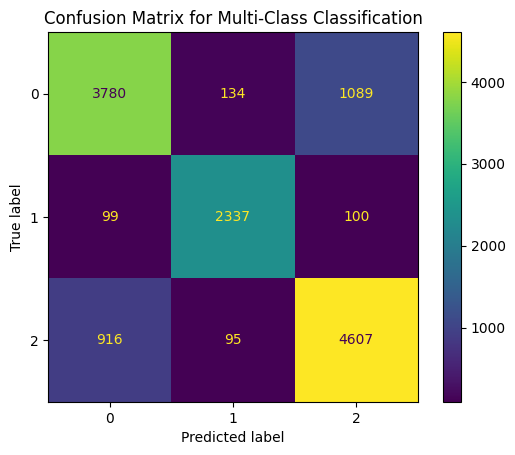

[2 2 2 ... 0 1 0]
[2 2 2 ... 0 1 2]


In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

_, predicted = torch.max(test_outputs.detach().cpu(), 1)  # Get the index of the max log-probability
labels_1d = torch.argmax(y_test, dim=1).cpu() # turn into 1D tensor

# Convert to numpy arrays
y_test_np = labels_1d.numpy()
predicted_np = predicted.numpy()

# Compute confusion matrix
cm = confusion_matrix(y_test_np, predicted_np)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion Matrix for Multi-Class Classification')
plt.show()

print(predicted_np)
print(y_test_np)

In [ ]:
import gc
# Free up GPU memory (testing)
print(f"Cached GPU memory before: {torch.cuda.memory_reserved()} bytes")
del model
del test_outputs
del y_test
del predicted
del labels_1d
del val_loader, test_loader, train_loader
del cm
gc.collect()
torch.cuda.empty_cache()
print(f"Cached GPU memory after: {torch.cuda.memory_reserved()} bytes")